# **Microscopy RGB Dataset Loader**

Notebook to load and visualize RGB images from the Microscopy dataset.  
**No** raw images or ISP pipeline are used. 

**RGB TIFF images (256×256) are loaded directly.**

In [1]:
import os
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import tifffile
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader

# ---------- CONFIGURATION ----------
ROOT_DIR = "C:\\Users\\gabriele.dangeli\\Dataset\\Microscopy" # TO BE UPDATED TO YOUR PATH
INTENSITY_RATIO = 1.0               # scale factor
MIN_SAMPLES_PER_CLASS = 5           # minimum samples per class threshold
BELOW_THRESHOLD_STRATEGY = 'drop'   # 'drop' or 'merge_to_rare'
RARE_CLASS_NAME = 'RARE'            # merged rare class name (if merge_to_rare)

print(f"Root directory: {ROOT_DIR}")
print(f"Exists: {os.path.exists(ROOT_DIR)}")

Root directory: C:\Users\gabriele.dangeli\Dataset\Microscopy
Exists: True


## Load annotations and RGB image paths

In [2]:
IMAGE_FILE_TYPES = {'dng', 'png', 'tif', 'tiff'}

VALID_CLASSES = [
    'BAS', 'EBO', 'EOS', 'KSC', 'LYA', 'LYT', 'MMZ', 'MOB',
    'MON', 'MYB', 'MYO', 'NGB', 'NGS', 'PMB', 'PMO', 'UNC'
]

# RGB-specific normalization statistics
DATASET_MEAN = [0.5566, 0.4607, 0.5923]
DATASET_STD  = [0.0983, 0.1417, 0.0667]

INVALID_FILES = {'Ma190c_lame3_zone13_composite_Mcropped_2.tiff'}

rgb_dir = os.path.join(ROOT_DIR, 'images', f'rgb_scale{int(INTENSITY_RATIO * 100):03d}')
label_file = os.path.join(ROOT_DIR, 'labels', 'Ma190c_annotations.dat')

print(f"RGB folder:    {rgb_dir}")
print(f"  Exists: {os.path.exists(rgb_dir)}")
print(f"Label file:    {label_file}")
print(f"  Exists: {os.path.exists(label_file)}")

RGB folder:    C:\Users\gabriele.dangeli\Dataset\Microscopy\images\rgb_scale100
  Exists: True
Label file:    C:\Users\gabriele.dangeli\Dataset\Microscopy\labels\Ma190c_annotations.dat
  Exists: True


In [3]:
def read_label_file(label_file_path: str):
    """Parse the Ma190c_annotations.dat annotation file."""
    images, class_labels = [], []
    with open(label_file_path, 'rb') as f:
        for line in f:
            line_decoded = line.decode('utf-8').strip()
            if not line_decoded:
                continue
            file_name, class_label = line_decoded.split()
            images.append(f"{file_name}.tiff")
            class_labels.append(class_label)
    return images, class_labels

images_filenames, class_labels_raw = read_label_file(label_file)
print(f"Total annotations: {len(images_filenames)}")
print(f"Classes found:     {sorted(set(class_labels_raw))}")

Total annotations: 950
Classes found:     ['BAD', 'BAS', 'EOS', 'KSC', 'LYA', 'LYT', 'MMZ', 'MON', 'MYO', 'NGB', 'NGS', 'UNC']


## Class filtering and dataset construction

In [4]:
# Per-class counts
label_counts = Counter(class_labels_raw)

# Keep only classes actually present in the annotations
valid_classes = [cls for cls in VALID_CLASSES if label_counts.get(cls, 0) > 0]

# Apply min_samples_per_class threshold
eligible_classes = [cls for cls in valid_classes if label_counts[cls] >= MIN_SAMPLES_PER_CLASS]
low_count_classes = [cls for cls in valid_classes if label_counts[cls] < MIN_SAMPLES_PER_CLASS]

# Build class mapping based on the chosen strategy
class_mapping = {}
if BELOW_THRESHOLD_STRATEGY == 'merge_to_rare':
    for cls in eligible_classes:
        class_mapping[cls] = cls
    for cls in low_count_classes:
        class_mapping[cls] = RARE_CLASS_NAME
    selected_classes = set(eligible_classes + low_count_classes)
else:  # 'drop'
    for cls in eligible_classes:
        class_mapping[cls] = cls
    selected_classes = set(eligible_classes)

print(f"Eligible classes (>= {MIN_SAMPLES_PER_CLASS} samples): {eligible_classes}")
print(f"Below-threshold classes (dropped/merged):              {low_count_classes}")
print(f"Selected classes:                                      {sorted(selected_classes)}")

Eligible classes (>= 5 samples): ['BAS', 'EOS', 'KSC', 'LYA', 'LYT', 'MON', 'NGB', 'NGS', 'UNC']
Below-threshold classes (dropped/merged):              ['MMZ', 'MYO']
Selected classes:                                      ['BAS', 'EOS', 'KSC', 'LYA', 'LYT', 'MON', 'NGB', 'NGS', 'UNC']


In [5]:
# Filter out invalid files and unselected classes
filtered_data = [
    (img, class_mapping[cls])
    for img, cls in zip(images_filenames, class_labels_raw)
    if cls in selected_classes and img not in INVALID_FILES
]

final_images, final_labels = zip(*filtered_data)

# Create class-to-index mapping
classes = sorted(set(final_labels))
if RARE_CLASS_NAME in classes:
    classes = [c for c in classes if c != RARE_CLASS_NAME] + [RARE_CLASS_NAME]
class_to_idx = {cls: i for i, cls in enumerate(classes)}

# Full paths to RGB images
image_paths = [os.path.join(rgb_dir, img) for img in final_images]
labels = [class_to_idx[lbl] for lbl in final_labels]

print(f"\nTotal images after filtering: {len(image_paths)}")
print(f"Final classes ({len(classes)}): {classes}")
print(f"Mapping: {class_to_idx}")


Total images after filtering: 940
Final classes (9): ['BAS', 'EOS', 'KSC', 'LYA', 'LYT', 'MON', 'NGB', 'NGS', 'UNC']
Mapping: {'BAS': 0, 'EOS': 1, 'KSC': 2, 'LYA': 3, 'LYT': 4, 'MON': 5, 'NGB': 6, 'NGS': 7, 'UNC': 8}


## Class distribution

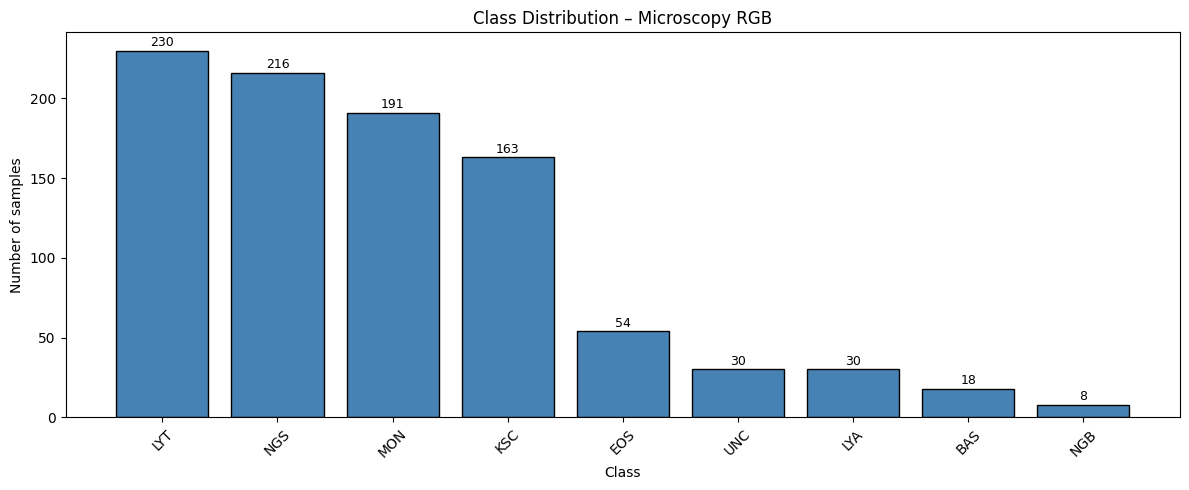


Per-class counts:
   LYT: 230
   NGS: 216
   MON: 191
   KSC: 163
   EOS: 54
   UNC: 30
   LYA: 30
   BAS: 18
   NGB: 8


In [6]:
# Class distribution
label_str = [classes[l] for l in labels]
counts = Counter(label_str)
sorted_counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

fig, ax = plt.subplots(figsize=(12, 5))
class_names_sorted = [c[0] for c in sorted_counts]
class_values = [c[1] for c in sorted_counts]
bars = ax.bar(class_names_sorted, class_values, color='steelblue', edgecolor='black')
ax.set_xlabel('Class')
ax.set_ylabel('Number of samples')
ax.set_title('Class Distribution – Microscopy RGB')
ax.tick_params(axis='x', rotation=45)
for bar, val in zip(bars, class_values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            str(val), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

print("\nPer-class counts:")
for name, count in sorted_counts:
    print(f"  {name:>4s}: {count}")

## **PyTorch Dataset for RGB images**

In [7]:
def load_image(path: str) -> tuple:
    """Load a TIFF image and return (float32 array, max value from dtype)."""
    raw = tifffile.imread(path)
    max_val = np.iinfo(raw.dtype).max if np.issubdtype(raw.dtype, np.integer) else 1.0
    return np.array(raw, dtype=np.float32), float(max_val)


class MicroscopyRGBDataset(Dataset):
    """
    PyTorch Dataset for the Microscopy RGB images.
    Loads 16-bit TIFF images, normalizes to [0, 1], and returns (C, H, W) tensors.
    """
    # Normalization statistics (computed on the filtered RGB split)
    dataset_mean = [0.5566, 0.4607, 0.5923]
    dataset_std  = [0.0983, 0.1417, 0.0667]

    def __init__(self, image_paths, labels, classes, transform=None, cache=True):
        self.image_paths = image_paths
        self.labels = labels
        self.classes = classes
        self.transform = transform
        self._use_cache = cache
        self._cache = {}

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        label = self.labels[idx]

        if self._use_cache and idx in self._cache:
            img = self._cache[idx]
        else:
            img, max_val = load_image(self.image_paths[idx])
            img = img / max_val  # normalize to [0, 1] (auto-detected from dtype)

            # Convert HWC -> CHW
            if img.ndim == 3 and img.shape[2] <= 4:
                img = torch.from_numpy(img).permute(2, 0, 1).float()
            elif img.ndim == 2:
                img = torch.from_numpy(img).float()
            else:
                img = torch.from_numpy(img).float()

            if self._use_cache:
                self._cache[idx] = img

        if self.transform is not None:
            img = self.transform(img)

        return img, label

    def __repr__(self):
        return (f"MicroscopyRGBDataset(n_images={len(self)}, "
                f"n_classes={len(self.classes)}, classes={self.classes})")


# Create the dataset
dataset = MicroscopyRGBDataset(
    image_paths=list(image_paths),
    labels=labels,
    classes=classes,
    cache=False,  # disable cache to save RAM; enable if memory is sufficient
)

print(dataset)
print(f"\nLoading first sample...")
img, lbl = dataset[0]
print(f"  Shape: {img.shape}")
print(f"  Dtype: {img.dtype}")
print(f"  Range: [{img.min():.4f}, {img.max():.4f}]")
print(f"  Label: {lbl} ({classes[lbl]})")

MicroscopyRGBDataset(n_images=940, n_classes=9, classes=['BAS', 'EOS', 'KSC', 'LYA', 'LYT', 'MON', 'NGB', 'NGS', 'UNC'])

Loading first sample...
  Shape: torch.Size([3, 256, 256])
  Dtype: torch.float32
  Range: [0.0409, 0.6747]
  Label: 7 (NGS)


## Sample visualization per class

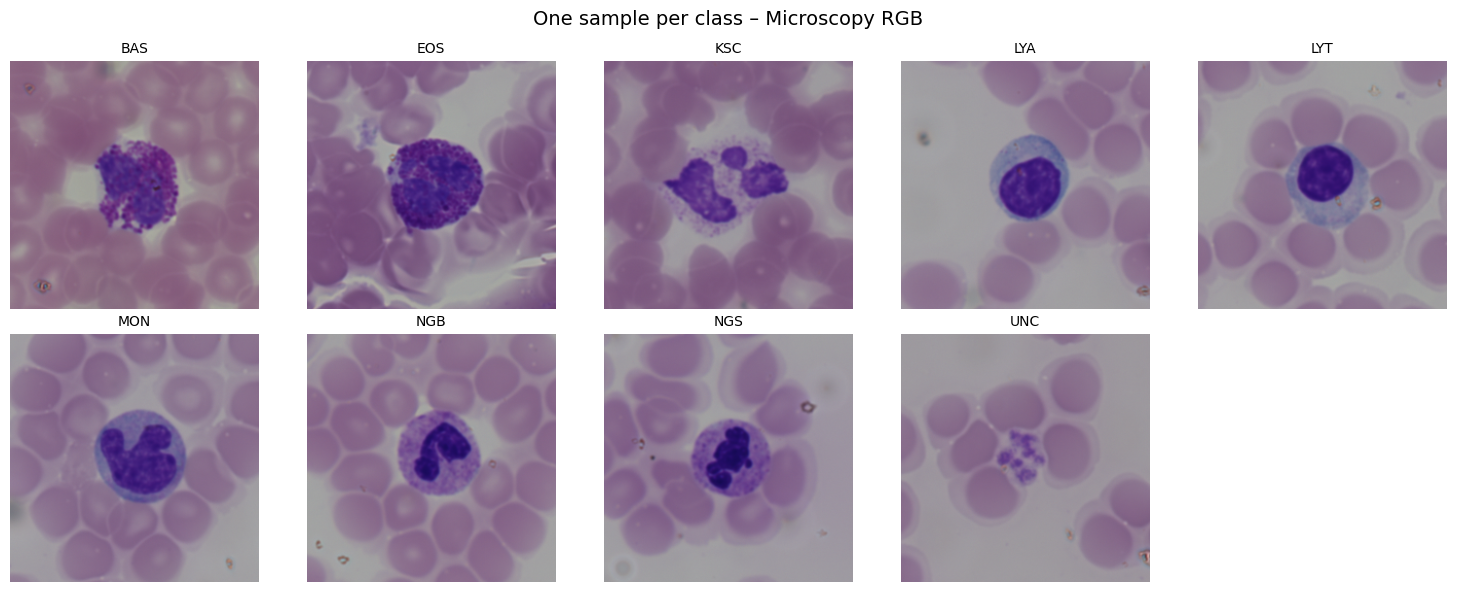

In [8]:
# Show one sample per class
n_classes = len(classes)
fig, axes = plt.subplots(2, (n_classes + 1) // 2, figsize=(3 * ((n_classes + 1) // 2), 6))
axes = axes.ravel()

# Find the first index for each class
class_first_idx = {}
for i, lbl in enumerate(labels):
    if lbl not in class_first_idx:
        class_first_idx[lbl] = i

for cls_idx in range(n_classes):
    ax = axes[cls_idx]
    if cls_idx in class_first_idx:
        img, _ = dataset[class_first_idx[cls_idx]]
        # CHW -> HWC for matplotlib
        img_np = img.permute(1, 2, 0).numpy()
        img_np = np.clip(img_np, 0, 1)
        ax.imshow(img_np)
    ax.set_title(classes[cls_idx], fontsize=10)
    ax.axis('off')

# Hide excess axes
for i in range(n_classes, len(axes)):
    axes[i].axis('off')

plt.suptitle('One sample per class – Microscopy RGB', fontsize=14)
plt.tight_layout()
plt.show()

## Training-ready DataLoader

In [9]:
from sklearn.model_selection import StratifiedShuffleSplit

# --- Stratified Train / Val split ---
SEED = 42
TRAIN_SIZE = 0.8
BATCH_SIZE = 32

y = np.array(labels)
sss = StratifiedShuffleSplit(n_splits=1, train_size=TRAIN_SIZE, random_state=SEED)
train_idx, val_idx = next(sss.split(np.zeros(len(y)), y))

train_dataset = torch.utils.data.Subset(dataset, train_idx.tolist())
val_dataset   = torch.utils.data.Subset(dataset, val_idx.tolist())

print(f"Train: {len(train_dataset)} images")
print(f"Val:   {len(val_dataset)} images")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Test batch
batch_imgs, batch_labels = next(iter(train_loader))
print(f"\nBatch shape:  {batch_imgs.shape}")
print(f"Batch labels: {batch_labels.tolist()[:10]}...")
print(f"Batch range:  [{batch_imgs.min():.4f}, {batch_imgs.max():.4f}]")

Train: 752 images
Val:   188 images

Batch shape:  torch.Size([32, 3, 256, 256])
Batch labels: [5, 4, 4, 3, 4, 0, 2, 7, 2, 2]...
Batch range:  [0.0307, 0.8558]


## Image grid from a training batch

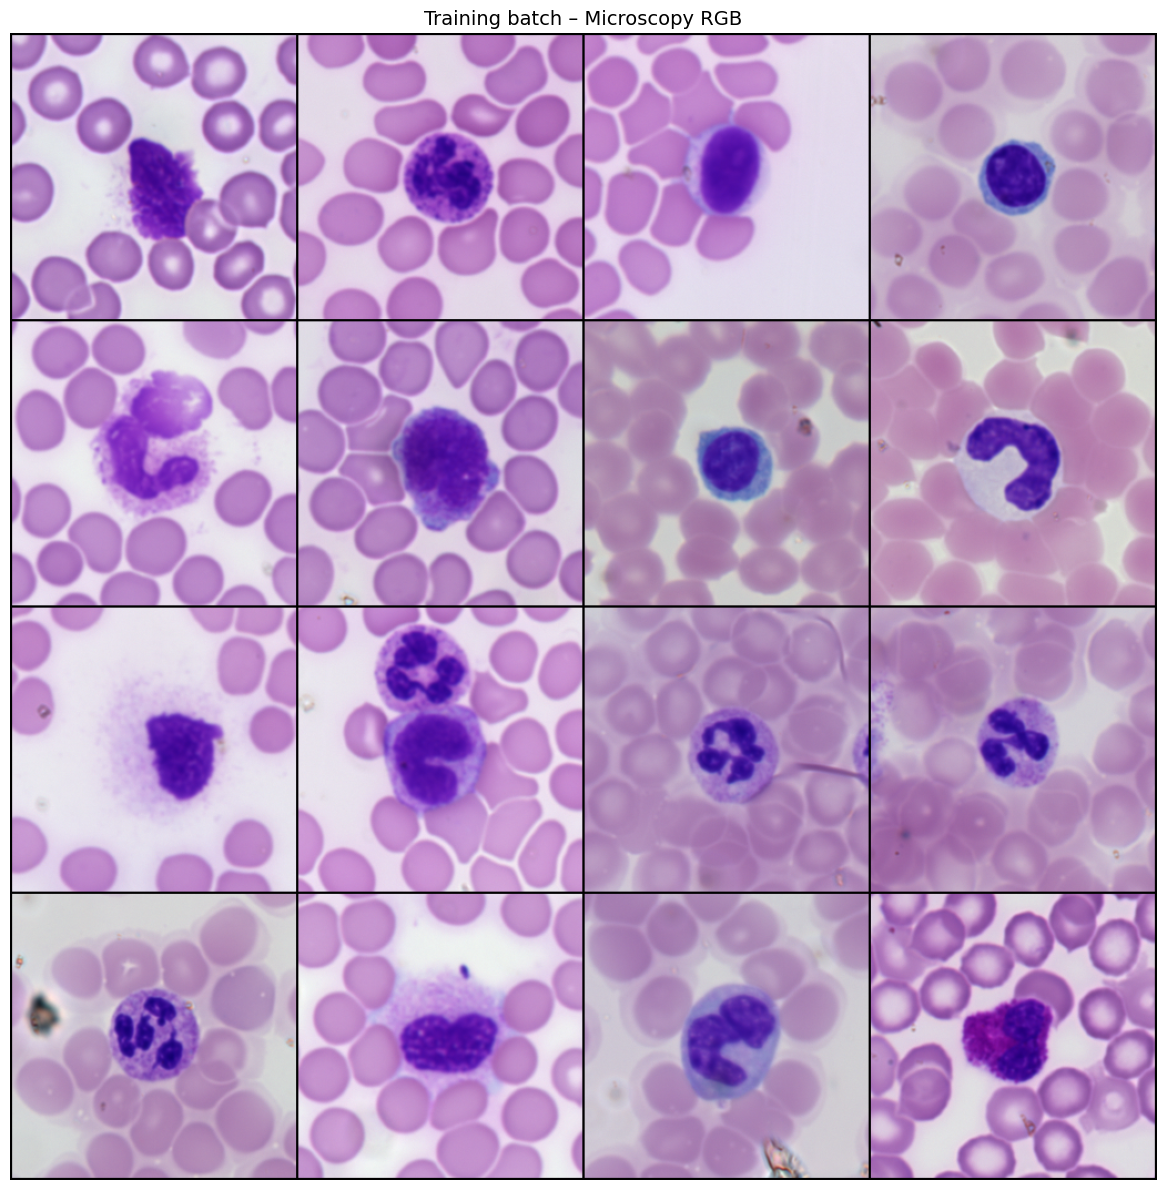

Labels: ['KSC', 'BAS', 'LYT', 'LYT', 'KSC', 'MON', 'LYT', 'NGB', 'KSC', 'MON', 'NGS', 'NGS', 'NGS', 'KSC', 'MON', 'EOS']


In [10]:
import torchvision.utils as vutils

# Grab a batch from the train loader
batch_imgs, batch_labels = next(iter(train_loader))

n_show = min(16, batch_imgs.shape[0])
grid = vutils.make_grid(batch_imgs[:n_show], nrow=4, normalize=True, padding=2)
grid_np = grid.permute(1, 2, 0).numpy()

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(grid_np)
ax.set_title('Training batch – Microscopy RGB', fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.show()

print("Labels:", [classes[l] for l in batch_labels[:n_show].tolist()])

## 9. Dataset summary

| Parameter | Value |
|---|---|
| Image type | RGB TIFF 16-bit |
| Resolution | 256 × 256 × 3 |
| Normalization | `img / np.iinfo(dtype).max` → \[0, 1\] (auto-detected) |
| Mean (dataset) | \[0.5566, 0.4607, 0.5923\] |
| Std (dataset) | \[0.0983, 0.1417, 0.0667\] |
| ISP Pipeline | **Not needed** (images are already RGB) |

---
# Benchmark: Classical SVM vs QSVM

The following cells use `dataset`, `labels`, `classes`, `train_idx`, `val_idx`
produced above to run a systematic benchmark of SVM (RBF kernel) vs QSVM
(quantum fidelity and density-matrix kernels) under ideal and noisy conditions.


## Parameters, binary sub-problem & PCA reduction


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import rbf_kernel

# ---------- BENCHMARK PARAMETERS ----------
class_pos = "NGS"
class_neg = "LYT"

n_train_per_class = 350
n_test_per_class  = 150
pca_dim           = 8       # number of PCA components = number of qubits for angle/ZZ
bits_per_feature  = 2       # basis encoding: pca_dim * bits = 16 qubits (sim-friendly)
seed = 0
rng  = np.random.default_rng(seed)

# PCA dimensions to sweep for classical SVM upper-bound analysis
pca_dims_sweep = [4, 8, 16, 32]

print(f"Available classes: {classes}")
print(f"Binary task: {class_pos} vs {class_neg}")
print(f"Quantum PCA dim: {pca_dim}  |  Basis qubits: {pca_dim * bits_per_feature}")
print(f"Classical SVM PCA sweep: {pca_dims_sweep}")


Available classes: ['BAS', 'EOS', 'KSC', 'LYA', 'LYT', 'MON', 'NGB', 'NGS', 'UNC']
Binary task: NGS vs LYT
Quantum PCA dim: 8  |  Basis qubits: 16
Classical SVM PCA sweep: [4, 8, 16, 32]


In [12]:
# --- Sample binary sub-problem from the full dataset ---
pos_idx = classes.index(class_pos)
neg_idx = classes.index(class_neg)
labels_arr = np.array(labels)

def sample_class_indices(split_idx, class_idx, n):
    """Sample up to n indices for a given class from a split."""
    candidates = split_idx[labels_arr[split_idx] == class_idx]
    return rng.choice(candidates, size=min(n, len(candidates)), replace=False)

tr_pos = sample_class_indices(train_idx, pos_idx, n_train_per_class)
tr_neg = sample_class_indices(train_idx, neg_idx, n_train_per_class)
te_pos = sample_class_indices(val_idx,   pos_idx, n_test_per_class)
te_neg = sample_class_indices(val_idx,   neg_idx, n_test_per_class)

tr_idx_bin = np.concatenate([tr_pos, tr_neg])
rng.shuffle(tr_idx_bin)
te_idx_bin = np.concatenate([te_pos, te_neg])
rng.shuffle(te_idx_bin)

def load_subset(idx_array, label_pos, label_neg):
    """Load images and encode labels as +1 / -1."""
    imgs, ys = [], []
    for i in idx_array:
        tensor, lbl = dataset[int(i)]
        arr = tensor.permute(1, 2, 0).numpy()
        imgs.append((arr * 255).clip(0, 255).astype(np.uint8))
        ys.append(1 if lbl == label_pos else -1)
    return np.array(imgs, dtype=np.uint8), np.array(ys, dtype=np.int64)

print(f"Loading {len(tr_idx_bin)} train images...")
X_train_img, y_train_bin = load_subset(tr_idx_bin, pos_idx, neg_idx)
print(f"Loading {len(te_idx_bin)} test images...")
X_test_img,  y_test_bin  = load_subset(te_idx_bin, pos_idx, neg_idx)
print(f"Train: {X_train_img.shape}, Test: {X_test_img.shape}")


Loading 357 train images...
Loading 89 test images...
Train: (357, 256, 256, 3), Test: (89, 256, 256, 3)


In [13]:
import gc, psutil

def mem_mb():
    return psutil.Process().memory_info().rss / 1024**2

# Flatten + normalize to [0, 1]
X_train_flat = X_train_img.reshape(len(X_train_img), -1).astype(np.float32) / 255.0
X_test_flat  = X_test_img.reshape(len(X_test_img),  -1).astype(np.float32) / 255.0
n_train = len(X_train_flat)

y_all    = np.concatenate([y_train_bin, y_test_bin])
y_binary = y_all.copy()
y_str    = np.where(y_all == 1, class_pos, class_neg)

print(f"RAM before PCA: {mem_mb():.0f} MB")
print(f"PCA {X_train_flat.shape[1]}D -> {pca_dim}D...")

pca_pre     = PCA(n_components=pca_dim, random_state=seed)
X_pca_train = pca_pre.fit_transform(X_train_flat)
X_pca_test  = pca_pre.transform(X_test_flat)

# Also store a higher-dim PCA projection for the classical SVM sweep
max_sweep_dim = max(pca_dims_sweep)
pca_sweep     = PCA(n_components=max_sweep_dim, random_state=seed)
X_sweep_train = pca_sweep.fit_transform(X_train_flat)
X_sweep_test  = pca_sweep.transform(X_test_flat)

# Release large flattened arrays immediately
del X_train_flat, X_test_flat, X_train_img, X_test_img
gc.collect()

# Stack train + test for embedding analysis
X_pca = np.vstack([X_pca_train, X_pca_test])

# Min-max normalize PCA features to [0, 1] (required for quantum encodings)
pca_min   = X_pca_train.min(axis=0)
pca_max   = X_pca_train.max(axis=0)
pca_range = np.where(pca_max - pca_min > 0, pca_max - pca_min, 1.0)
X_pca_norm_train = (X_pca_train - pca_min) / pca_range
X_pca_norm_test  = np.clip((X_pca_test - pca_min) / pca_range, 0.0, 1.0)
X_pca_norm       = np.vstack([X_pca_norm_train, X_pca_norm_test])

del X_pca_train, X_pca_test
gc.collect()

print(f"Explained variance ({pca_dim} comp): {pca_pre.explained_variance_ratio_.sum():.3f}")
print(f"Explained variance ({max_sweep_dim} comp): {pca_sweep.explained_variance_ratio_.sum():.3f}")
print(f"X_pca_norm: {X_pca_norm.shape}  ({X_pca_norm.nbytes/1024:.1f} KB)")
print(f"RAM after PCA: {mem_mb():.0f} MB")


RAM before PCA: 1311 MB
PCA 196608D -> 8D...
Explained variance (8 comp): 0.332
Explained variance (32 comp): 0.573
X_pca_norm: (446, 8)  (13.9 KB)
RAM after PCA: 965 MB


In [14]:
# ============================================================
# Quantum encoding circuits & helper functions
# ============================================================

def angle_encoding(features):
    """Angle (rotation) encoding: RY(f*pi) on each qubit + CNOT chain."""
    n = len(features)
    qc = QuantumCircuit(n)
    for i, f in enumerate(features):
        qc.ry(f * np.pi, i)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    return qc


def amplitude_z_expectations(features):
    """Amplitude encoding via pure NumPy (no Qiskit circuit).
    Normalizes the feature vector, computes probabilities in the
    computational basis, then returns <Z>_i for each qubit.
    NOTE: this is a classical emulation — noise cannot be applied.
    """
    v = np.asarray(features, dtype=float)
    norm = np.linalg.norm(v)
    if norm > 0:
        v = v / norm
    n_qubits = int(np.ceil(np.log2(max(len(v), 2))))
    padded = np.zeros(2**n_qubits)
    padded[:len(v)] = v
    probs   = padded ** 2
    indices = np.arange(2**n_qubits)
    result  = np.zeros(n_qubits)
    for i in range(n_qubits):
        bit_i = (indices >> (n_qubits - 1 - i)) & 1
        result[i] = probs[bit_i == 0].sum() - probs[bit_i == 1].sum()
    return result


def basis_encoding(features, bits=2):
    """Basis encoding: discretize each feature to `bits`-bit integer, encode via X gates.
    With pca_dim=8 and bits=2 this gives 16 qubits (sim-friendly).
    WARNING: continuous features mapped to a discrete basis produce a quasi-diagonal
    kernel matrix, which severely limits generalization.
    """
    n_qubits = len(features) * bits
    qc = QuantumCircuit(n_qubits)
    qubit_idx = 0
    for f in features:
        int_val = int(round(float(f) * (2**bits - 1)))
        int_val = max(0, min(int_val, 2**bits - 1))
        for bit in format(int_val, f"0{bits}b"):
            if bit == "1":
                qc.x(qubit_idx)
            qubit_idx += 1
    return qc


def z_expectations(qc):
    """Compute <Z>_i for each qubit from the ideal statevector."""
    sv = Statevector.from_instruction(qc)
    probs   = np.abs(sv.data) ** 2
    n       = qc.num_qubits
    indices = np.arange(2**n)
    result  = np.zeros(n)
    for i in range(n):
        bit_i = (indices >> (n - 1 - i)) & 1
        result[i] = probs[bit_i == 0].sum() - probs[bit_i == 1].sum()
    return result


# --- Noise model ---
def build_noise_model(p_single=0.001, p_two=0.01, p_readout=0.01):
    """Depolarizing noise model for 1-qubit, 2-qubit gates and readout."""
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p_single, 1), ["rx", "ry", "rz", "h", "x"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p_two,    2), ["cx", "cz"])
    nm.add_all_qubit_readout_error([[1 - p_readout, p_readout], [p_readout, 1 - p_readout]])
    return nm

noisy_sim = AerSimulator(method="density_matrix", noise_model=build_noise_model())


def z_expectations_noisy(qc, sim=None):
    """Compute <Z>_i for each qubit from the noisy density matrix."""
    if sim is None:
        sim = noisy_sim
    qc_d = transpile(qc, basis_gates=["cx", "u", "x", "ry", "rz", "h", "reset"],
                     coupling_map=None, optimization_level=0)
    qc_d.save_density_matrix()
    dm = DensityMatrix(sim.run(qc_d).result().data()["density_matrix"])
    pauli_z = np.array([[1, 0], [0, -1]])
    n = qc.num_qubits
    return np.array([
        np.real(np.trace(partial_trace(dm, [j for j in range(n) if j != i]).data @ pauli_z))
        for i in range(n)
    ])


print("Encoding functions defined.")
print(f"  Angle encoding:     {pca_dim} qubits")
print(f"  Amplitude encoding: {int(np.ceil(np.log2(max(pca_dim, 2))))} qubits (numpy emulation)")
print(f"  Basis encoding:     {pca_dim * bits_per_feature} qubits ({bits_per_feature} bits/feature)")


Encoding functions defined.
  Angle encoding:     8 qubits
  Amplitude encoding: 3 qubits (numpy emulation)
  Basis encoding:     16 qubits (2 bits/feature)


In [15]:
import gc

def embed_batch(circuit_fn, data, expectation_fn=z_expectations, batch_size=50):
    """Embed data in batches using a circuit function and an expectation function.
    Use expectation_fn=z_expectations for ideal, z_expectations_noisy for noisy.
    """
    result = []
    for start in range(0, len(data), batch_size):
        batch = data[start:start + batch_size]
        circuits = [circuit_fn(s) for s in batch]
        result.extend([expectation_fn(c) for c in circuits])
        del circuits
        gc.collect()
    return np.array(result)


# ========== IDEAL EMBEDDINGS ==========
print("Computing ideal embeddings...")

datasets = {"Classical (PCA)": X_pca.copy()}

print("  Angle encoding...")
datasets["Angle"] = embed_batch(angle_encoding, X_pca_norm)
gc.collect()

print("  Amplitude encoding (numpy emulation)...")
datasets["Amplitude"] = np.array([amplitude_z_expectations(s) for s in X_pca_norm])
gc.collect()

print("  Basis encoding...")
datasets["Basis"] = embed_batch(
    lambda f: basis_encoding(f, bits=bits_per_feature), X_pca_norm
)
gc.collect()

print("Ideal embeddings done.")
for name, arr in datasets.items():
    print(f"  {name}: {arr.shape}")
print(f"RAM: {mem_mb():.0f} MB")


# ========== NOISY EMBEDDINGS ==========
# NOTE: Amplitude encoding is a pure numpy emulation — noise cannot be applied.
#       It is excluded from the noisy comparison.
print("\nComputing noisy embeddings (density matrix simulation)...")
datasets_noisy = {}

print("  Angle encoding (noisy)...")
datasets_noisy["Angle (noisy)"] = embed_batch(
    angle_encoding, X_pca_norm,
    expectation_fn=z_expectations_noisy,
    batch_size=20  # smaller batches for density matrix overhead
)
gc.collect()

print("Noisy embeddings done.")
for name, arr in datasets_noisy.items():
    print(f"  {name}: {arr.shape}")
print(f"RAM: {mem_mb():.0f} MB")


Computing ideal embeddings...
  Angle encoding...
  Amplitude encoding (numpy emulation)...
  Basis encoding...
Ideal embeddings done.
  Classical (PCA): (446, 8)
  Angle: (446, 8)
  Amplitude: (446, 3)
  Basis: (446, 16)
RAM: 966 MB

Computing noisy embeddings (density matrix simulation)...
  Angle encoding (noisy)...
Noisy embeddings done.
  Angle (noisy): (446, 8)
RAM: 972 MB


In [16]:
# ============================================================
# Separability metrics: Fisher Ratio, Silhouette, KTA
# ============================================================

def fisher_ratio_matrix(X, y):
    """Compute trace(S_W^-1 @ S_B) — multivariate Fisher discriminant ratio."""
    cls_list = np.unique(y)
    mu_global = X.mean(axis=0)
    S_W = np.zeros((X.shape[1], X.shape[1]))
    S_B = np.zeros((X.shape[1], X.shape[1]))
    for c in cls_list:
        Xc   = X[y == c]
        mu_c = Xc.mean(axis=0)
        S_W += (Xc - mu_c).T @ (Xc - mu_c)
        diff = (mu_c - mu_global).reshape(-1, 1)
        S_B += len(Xc) * (diff @ diff.T)
    ridge = 1e-6 * np.trace(S_W) / X.shape[1] * np.eye(X.shape[1])
    try:
        return np.trace(np.linalg.solve(S_W + ridge, S_B))
    except np.linalg.LinAlgError:
        return np.trace(np.linalg.pinv(S_W + ridge) @ S_B)


def compute_separability(X_embed, y_labels, name):
    """Compute Fisher Ratio, Silhouette score, and Kernel-Target Alignment."""
    X_embed = np.asarray(X_embed)
    if X_embed.ndim == 1:
        X_embed = X_embed.reshape(-1, 1)
    fr    = fisher_ratio_matrix(X_embed, y_labels)
    gamma = 1.0 / (X_embed.shape[1] * X_embed.var()) if X_embed.var() > 0 else 1.0
    K     = rbf_kernel(X_embed, gamma=gamma)
    L     = np.outer(y_labels, y_labels)
    kta   = np.sum(K * L) / np.sqrt(np.sum(K**2) * np.sum(L**2))
    return {
        "Encoding": name, "Dimension": X_embed.shape[1],
        "Fisher Ratio": fr,
        "Silhouette": silhouette_score(X_embed, y_labels),
        "KTA": kta,
    }


results_ideal = [compute_separability(X, y_binary, n) for n, X in datasets.items()]
results_noisy = [compute_separability(X, y_binary, n) for n, X in datasets_noisy.items()]

print("Ideal embeddings — separability metrics:")
print(pd.DataFrame(results_ideal).round(4).to_string(index=False))

if results_noisy:
    print("\nNoisy embeddings — separability metrics:")
    print(pd.DataFrame(results_noisy).round(4).to_string(index=False))

# Side-by-side comparison (quantum encodings only)
df_ideal_q = pd.DataFrame(results_ideal[1:]).set_index("Encoding")[["Fisher Ratio", "Silhouette", "KTA"]]
if results_noisy:
    df_noisy_q = pd.DataFrame(results_noisy).set_index("Encoding")[["Fisher Ratio", "Silhouette", "KTA"]]
    # Align index names for join
    df_noisy_q.index = [n.replace(" (noisy)", "") for n in df_noisy_q.index]
    df_sep_cmp = df_ideal_q.join(df_noisy_q, lsuffix=" (ideal)", rsuffix=" (noisy)", how="outer")
    print(f"\nSeparability comparison — {class_pos} vs {class_neg}")
    print(df_sep_cmp.round(4).to_string())


Ideal embeddings — separability metrics:
       Encoding  Dimension  Fisher Ratio  Silhouette    KTA
Classical (PCA)          8        0.5254      0.0629 0.0599
          Angle          8        0.1664      0.0606 0.0373
      Amplitude          3        0.1251      0.0385 0.0317
          Basis         16        0.3737      0.0235 0.0366

Noisy embeddings — separability metrics:
     Encoding  Dimension  Fisher Ratio  Silhouette    KTA
Angle (noisy)          8        0.1664      0.0609 0.0374

Separability comparison — NGS vs LYT
           Fisher Ratio (ideal)  Silhouette (ideal)  KTA (ideal)  Fisher Ratio (noisy)  Silhouette (noisy)  KTA (noisy)
Encoding                                                                                                               
Amplitude                0.1251              0.0385       0.0317                   NaN                 NaN          NaN
Angle                    0.1664              0.0606       0.0373                0.1664              0.0

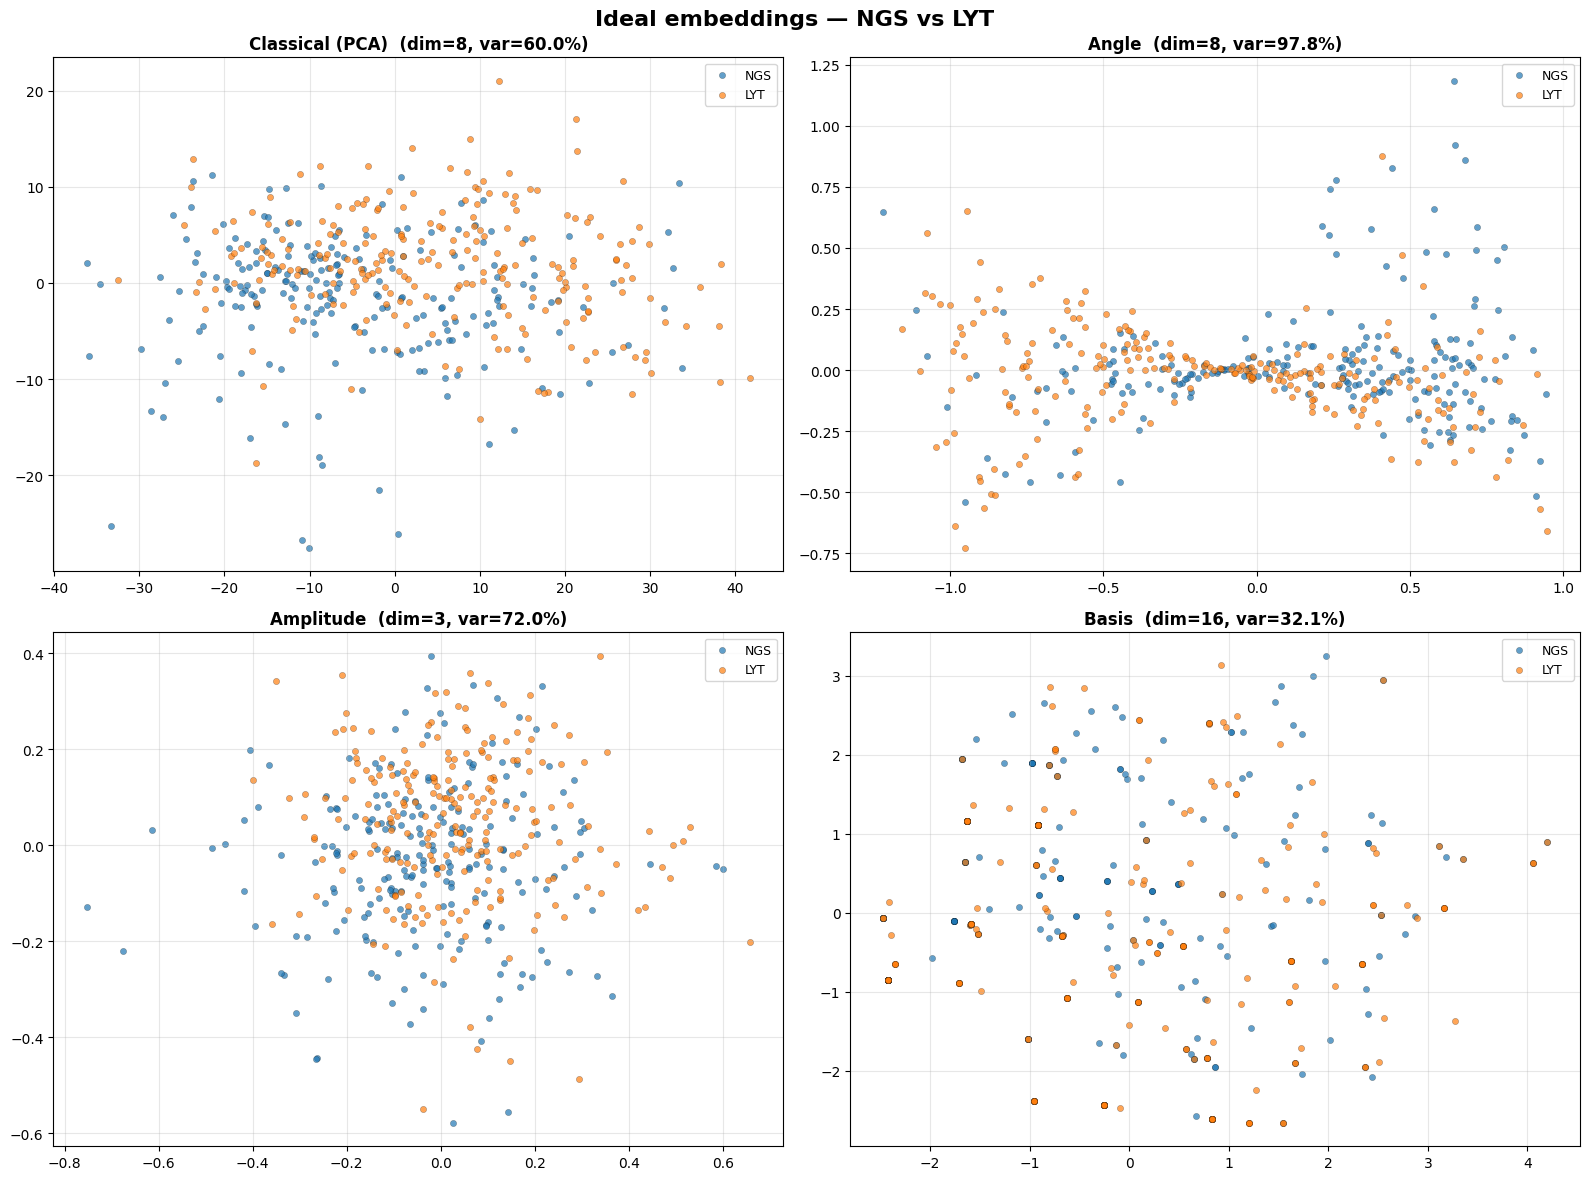

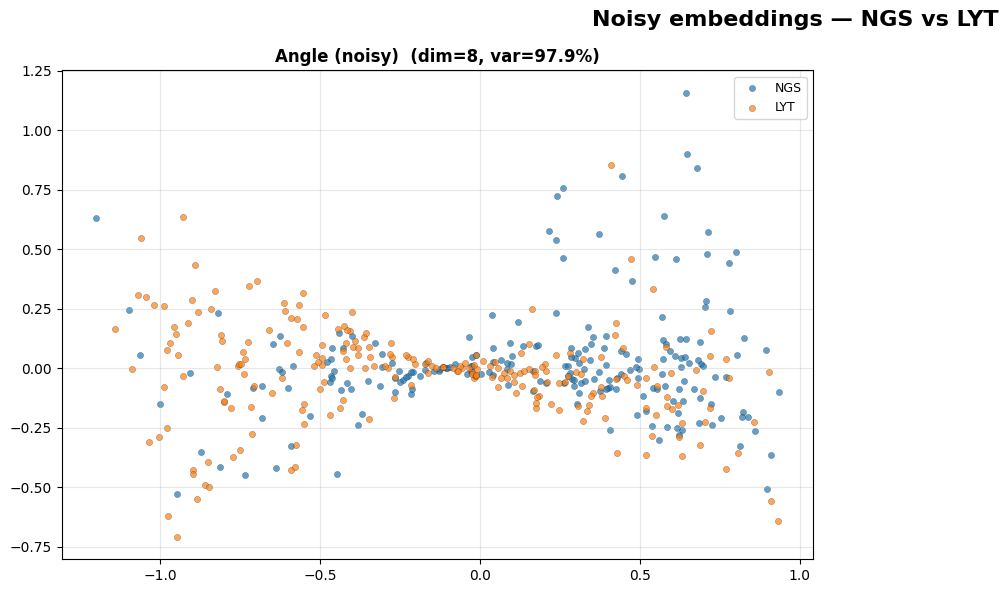

In [17]:
# ============================================================
# Embedding visualization (PCA projection to 2D)
# ============================================================

def plot_embeddings(dataset_dict, title):
    """Scatter-plot each embedding projected to 2D via PCA."""
    ncols = 2
    nrows = (len(dataset_dict) + 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 6 * nrows))
    if nrows == 1:
        axes = np.atleast_2d(axes)
    for (name, X_embed), ax in zip(dataset_dict.items(), axes.flat):
        X_embed = np.asarray(X_embed)
        if X_embed.ndim == 1:
            X_embed = X_embed.reshape(-1, 1)
        n_comp = min(2, X_embed.shape[1])
        pca_viz      = PCA(n_components=n_comp, random_state=seed)
        X_proj_train = pca_viz.fit_transform(X_embed[:n_train])
        X_proj_test  = pca_viz.transform(X_embed[n_train:])
        X_proj       = np.vstack([X_proj_train, X_proj_test])
        var          = pca_viz.explained_variance_ratio_.sum()
        if n_comp == 1:
            data_cls = [X_proj[y_str == class_pos, 0], X_proj[y_str == class_neg, 0]]
            ax.violinplot(data_cls, positions=[0, 1], showmedians=True, widths=0.4)
            ax.set_xticks([0, 1])
            ax.set_xticklabels([class_pos, class_neg])
        else:
            for cls_name, color in [(class_pos, "tab:blue"), (class_neg, "tab:orange")]:
                mask = y_str == cls_name
                ax.scatter(X_proj[mask, 0], X_proj[mask, 1], c=color,
                           label=cls_name, alpha=0.7, s=20, edgecolors="k", linewidth=0.2)
            ax.legend(fontsize=9)
        ax.set_title(f"{name}  (dim={X_embed.shape[1]}, var={var:.1%})", fontweight="bold")
        ax.grid(alpha=0.3)
    for ax in list(axes.flat)[len(dataset_dict):]:
        ax.set_visible(False)
    plt.suptitle(title, fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_embeddings(datasets,       f"Ideal embeddings — {class_pos} vs {class_neg}")
if datasets_noisy:
    plot_embeddings(datasets_noisy, f"Noisy embeddings — {class_pos} vs {class_neg}")


## Classical SVM baseline (RBF kernel)

GridSearch 5-fold over C and gamma for each encoding type.
Also runs a **PCA dimension sweep** (classical SVM only) to establish an upper bound
that is not constrained by the number of qubits.


In [18]:
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, roc_curve, auc)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

cv_svm = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
svm_pipeline   = Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf"))])
param_grid_svm = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1]}

# --- SVM on quantum-encoding embeddings ---
svm_rows = []
svm_predictions = {}   # store predictions for confusion matrices later

for name, X_embed in datasets.items():
    X_embed = np.asarray(X_embed)
    if X_embed.ndim == 1:
        X_embed = X_embed.reshape(-1, 1)
    X_tr, X_te = X_embed[:n_train], X_embed[n_train:]
    gs = GridSearchCV(svm_pipeline, param_grid_svm, scoring="f1", cv=cv_svm, n_jobs=-1, refit=True)
    gs.fit(X_tr, y_train_bin)
    y_pred = gs.best_estimator_.predict(X_te)
    svm_predictions[name] = y_pred
    svm_rows.append({
        "Encoding":         name,
        "Dim":              X_embed.shape[1],
        "Best_C":           gs.best_params_["svc__C"],
        "Best_gamma":       gs.best_params_["svc__gamma"],
        "CV_best_f1":       gs.best_score_,
        "Accuracy_test":    accuracy_score(y_test_bin, y_pred),
        "F1_test":          f1_score(y_test_bin, y_pred, pos_label=1),
        "BalancedAcc_test": balanced_accuracy_score(y_test_bin, y_pred),
    })
    r = svm_rows[-1]
    print(f"{name}: Acc={r['Accuracy_test']:.4f}  F1={r['F1_test']:.4f}  "
          f"BAcc={r['BalancedAcc_test']:.4f}  (C={r['Best_C']}, gamma={r['Best_gamma']})")

df_svm = pd.DataFrame(svm_rows).sort_values("F1_test", ascending=False)

# --- PCA dimension sweep (classical SVM upper bound) ---
print(f"\n{'='*60}")
print("PCA dimension sweep — Classical SVM (RBF) upper bound")
print(f"{'='*60}")
sweep_rows = []
for dim in pca_dims_sweep:
    X_tr_s = X_sweep_train[:, :dim]
    X_te_s = X_sweep_test[:, :dim]
    var_expl = pca_sweep.explained_variance_ratio_[:dim].sum()
    gs_s = GridSearchCV(svm_pipeline, param_grid_svm, scoring="f1", cv=cv_svm, n_jobs=-1, refit=True)
    gs_s.fit(X_tr_s, y_train_bin)
    y_pred_s = gs_s.best_estimator_.predict(X_te_s)
    sweep_rows.append({
        "PCA_dim":          dim,
        "Var_explained":    var_expl,
        "Best_C":           gs_s.best_params_["svc__C"],
        "Best_gamma":       gs_s.best_params_["svc__gamma"],
        "Accuracy_test":    accuracy_score(y_test_bin, y_pred_s),
        "F1_test":          f1_score(y_test_bin, y_pred_s, pos_label=1),
        "BalancedAcc_test": balanced_accuracy_score(y_test_bin, y_pred_s),
    })
    r = sweep_rows[-1]
    print(f"  dim={dim:3d}  var={var_expl:.3f}  Acc={r['Accuracy_test']:.4f}  "
          f"F1={r['F1_test']:.4f}  BAcc={r['BalancedAcc_test']:.4f}")

df_sweep = pd.DataFrame(sweep_rows)

# Store the best classical F1 for later comparison
best_classical_f1 = df_sweep["F1_test"].max()
best_classical_dim = df_sweep.loc[df_sweep["F1_test"].idxmax(), "PCA_dim"]
print(f"\nBest classical SVM: F1={best_classical_f1:.4f} at PCA dim={best_classical_dim}")

print(f"\nSVM RBF on embeddings — {class_pos} vs {class_neg}, pca_dim={pca_dim}")
print(df_svm.round(4).to_string(index=False))
print(f"\nSVM RBF dimension sweep:")
print(df_sweep.round(4).to_string(index=False))


Classical (PCA): Acc=0.7865  F1=0.7711  BAcc=0.7851  (C=1, gamma=0.01)
Angle: Acc=0.6966  F1=0.6747  BAcc=0.6951  (C=1, gamma=0.01)
Amplitude: Acc=0.7528  F1=0.7250  BAcc=0.7503  (C=1, gamma=1)
Basis: Acc=0.6517  F1=0.6353  BAcc=0.6509  (C=100, gamma=scale)

PCA dimension sweep — Classical SVM (RBF) upper bound
  dim=  4  var=0.255  Acc=0.7528  F1=0.7381  BAcc=0.7518
  dim=  8  var=0.332  Acc=0.7865  F1=0.7711  BAcc=0.7851
  dim= 16  var=0.439  Acc=0.8764  F1=0.8764  BAcc=0.8774
  dim= 32  var=0.573  Acc=0.8202  F1=0.8140  BAcc=0.8200

Best classical SVM: F1=0.8764 at PCA dim=16

SVM RBF on embeddings — NGS vs LYT, pca_dim=8
       Encoding  Dim  Best_C Best_gamma  CV_best_f1  Accuracy_test  F1_test  BalancedAcc_test
Classical (PCA)    8       1       0.01      0.7847         0.7865   0.7711            0.7851
      Amplitude    3       1          1      0.6227         0.7528   0.7250            0.7503
          Angle    8       1       0.01      0.6381         0.6966   0.6747          

## QSVM — Quantum kernels

Kernel matrices are computed directly from quantum circuits:
- **Ideal**: fidelity kernel $K(a,b)=|\langle\phi(a)|\phi(b)\rangle|^2$ via statevector simulation.
- **Noisy**: density-matrix kernel $K(a,b)=\mathrm{Tr}(\rho_a\,\rho_b)$ via `AerSimulator` with depolarizing noise.

An SVC with `kernel='precomputed'` is then trained on each kernel matrix.


In [19]:
import time
from qiskit.circuit.library import zz_feature_map

X_train_q = X_pca_norm[:n_train]
X_test_q  = X_pca_norm[n_train:]

# ============================================================
# Quantum kernel functions
# ============================================================

def compute_fidelity_kernel(circuit_fn, X_a, X_b):
    """Ideal fidelity kernel: K(a,b) = |<phi(a)|phi(b)>|^2"""
    svecs_a = np.array([Statevector.from_instruction(circuit_fn(x)).data for x in X_a])
    svecs_b = np.array([Statevector.from_instruction(circuit_fn(x)).data for x in X_b])
    return np.abs(svecs_a @ svecs_b.conj().T) ** 2


def compute_basis_kernel(X_a, X_b, bits=bits_per_feature):
    """Basis kernel: K(a,b) = 1 if same bit-string, 0 otherwise.
    WARNING: maps continuous features to integers — produces a quasi-diagonal
    kernel matrix with poor generalization on continuous data.
    """
    def to_int(x):
        idx = 0
        for f in x:
            idx = (idx << bits) | int(f * (2**bits - 1))
        return idx
    ia = np.array([to_int(x) for x in X_a])
    ib = np.array([to_int(x) for x in X_b])
    return (ia[:, None] == ib[None, :]).astype(float)


def compute_amplitude_kernel(X_a, X_b):
    """Amplitude kernel via numpy emulation: K = (emb_a @ emb_b.T)^2.
    NOTE: purely classical — noise is not applicable.
    """
    emb_a = np.array([amplitude_z_expectations(x) for x in X_a])
    emb_b = np.array([amplitude_z_expectations(x) for x in X_b])
    norm_a = np.linalg.norm(emb_a, axis=1, keepdims=True)
    norm_b = np.linalg.norm(emb_b, axis=1, keepdims=True)
    emb_a = emb_a / np.where(norm_a > 0, norm_a, 1)
    emb_b = emb_b / np.where(norm_b > 0, norm_b, 1)
    return (emb_a @ emb_b.T) ** 2


def get_density_matrix(circuit_fn, x, sim):
    """Run a circuit through a noisy simulator and return the density matrix."""
    qc = circuit_fn(x)
    qc_d = transpile(qc, basis_gates=["cx", "u", "x", "ry", "rz", "h", "reset"],
                     coupling_map=None, optimization_level=0)
    qc_d.save_density_matrix()
    return sim.run(qc_d).result().data()["density_matrix"].data


def compute_dm_kernel(circuit_fn, X_a, X_b, sim=None):
    """Noisy density-matrix kernel: K(a,b) = Tr(rho_a @ rho_b)"""
    if sim is None:
        sim = noisy_sim
    rho_a = np.array([get_density_matrix(circuit_fn, x, sim) for x in X_a])
    rho_b = np.array([get_density_matrix(circuit_fn, x, sim) for x in X_b])
    return np.real(np.einsum("aij,bji->ab", rho_a, rho_b))


# --- ZZFeatureMap circuit ---
_zz_feature_map = zz_feature_map(feature_dimension=pca_dim, reps=1)

def zz_circuit(x):
    return _zz_feature_map.assign_parameters(
        dict(zip(_zz_feature_map.parameters, x * np.pi)))

# Add ZZFeatureMap ideal embedding to datasets
print("Computing ZZFeatureMap ideal embedding...")
datasets["ZZFeatureMap"] = np.array([z_expectations(zz_circuit(s)) for s in X_pca_norm])
print(f"  ZZFeatureMap: {datasets['ZZFeatureMap'].shape}")

print("\nQuantum kernel functions defined.")


Computing ZZFeatureMap ideal embedding...
  ZZFeatureMap: (446, 8)

Quantum kernel functions defined.


In [20]:
# ============================================================
# QSVM training — ideal and noisy kernels
# ============================================================

qsvm_kernels = {
    "QSVM Angle":        lambda Xa, Xb: compute_fidelity_kernel(angle_encoding, Xa, Xb),
    "QSVM Amplitude":    lambda Xa, Xb: compute_amplitude_kernel(Xa, Xb),
    "QSVM Basis":        lambda Xa, Xb: compute_basis_kernel(Xa, Xb),
    "QSVM ZZFeatureMap": lambda Xa, Xb: compute_fidelity_kernel(zz_circuit, Xa, Xb),
}

qsvm_noisy_kernels = {
    "QSVM Angle (noisy)":        lambda Xa, Xb: compute_dm_kernel(angle_encoding, Xa, Xb),
    # Amplitude is pure numpy — no noise applicable, excluded from noisy comparison
    "QSVM ZZFeatureMap (noisy)": lambda Xa, Xb: compute_dm_kernel(zz_circuit, Xa, Xb),
}

param_grid_qsvm = {"C": [0.1, 1, 10, 100]}
cv_qsvm = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)


def run_qsvm(kernel_dict, X_tr, X_te, y_tr, y_te):
    """Train SVC(kernel='precomputed') with GridSearchCV for each quantum kernel."""
    rows = []
    predictions = {}
    for name, kernel_fn in kernel_dict.items():
        print(f"\n{name}")
        t0 = time.time()
        print(f"  K_train ({len(X_tr)}x{len(X_tr)})...", end=" ", flush=True)
        K_train = kernel_fn(X_tr, X_tr)
        print(f"{time.time()-t0:.1f}s")
        t0 = time.time()
        print(f"  K_test  ({len(X_te)}x{len(X_tr)})...", end=" ", flush=True)
        K_test = kernel_fn(X_te, X_tr)
        print(f"{time.time()-t0:.1f}s")

        gs = GridSearchCV(SVC(kernel="precomputed"), param_grid_qsvm,
                          scoring="f1", cv=cv_qsvm, refit=True)
        gs.fit(K_train, y_tr)
        y_pred = gs.best_estimator_.predict(K_test)
        predictions[name] = y_pred
        row = {
            "Encoding":         name,
            "Best_C":           gs.best_params_["C"],
            "CV_best_f1":       gs.best_score_,
            "Accuracy_test":    accuracy_score(y_te, y_pred),
            "F1_test":          f1_score(y_te, y_pred, pos_label=1),
            "BalancedAcc_test": balanced_accuracy_score(y_te, y_pred),
        }
        rows.append(row)
        print(f"  Acc={row['Accuracy_test']:.4f}  F1={row['F1_test']:.4f}  "
              f"BAcc={row['BalancedAcc_test']:.4f}  (C={row['Best_C']})")
    return pd.DataFrame(rows).sort_values("F1_test", ascending=False), predictions


print("Training QSVM — ideal kernels...")
df_qsvm, qsvm_preds = run_qsvm(qsvm_kernels, X_train_q, X_test_q, y_train_bin, y_test_bin)

print("\nTraining QSVM — noisy kernels...")
df_qsvm_noisy, qsvm_noisy_preds = run_qsvm(qsvm_noisy_kernels, X_train_q, X_test_q, y_train_bin, y_test_bin)

print(f"\nQSVM Ideal — {class_pos} vs {class_neg}, pca_dim={pca_dim}")
print(df_qsvm.round(4).to_string(index=False))
print(f"\nQSVM Noisy — {class_pos} vs {class_neg}, pca_dim={pca_dim}")
print(df_qsvm_noisy.round(4).to_string(index=False))


Training QSVM — ideal kernels...

QSVM Angle
  K_train (357x357)... 1.1s
  K_test  (89x357)... 0.7s
  Acc=0.7753  F1=0.7619  BAcc=0.7743  (C=1)

QSVM Amplitude
  K_train (357x357)... 0.0s
  K_test  (89x357)... 0.0s
  Acc=0.6404  F1=0.6364  BAcc=0.6408  (C=1)

QSVM Basis
  K_train (357x357)... 0.0s
  K_test  (89x357)... 0.0s
  Acc=0.5843  F1=0.4789  BAcc=0.5781  (C=1)

QSVM ZZFeatureMap
  K_train (357x357)... 5.2s
  K_test  (89x357)... 3.3s
  Acc=0.7303  F1=0.7273  BAcc=0.7308  (C=10)

Training QSVM — noisy kernels...

QSVM Angle (noisy)
  K_train (357x357)... 99.1s
  K_test  (89x357)... 26.6s
  Acc=0.7640  F1=0.7470  BAcc=0.7626  (C=1)

QSVM ZZFeatureMap (noisy)
  K_train (357x357)... 104.5s
  K_test  (89x357)... 32.6s
  Acc=0.7303  F1=0.7273  BAcc=0.7308  (C=10)

QSVM Ideal — NGS vs LYT, pca_dim=8
         Encoding  Best_C  CV_best_f1  Accuracy_test  F1_test  BalancedAcc_test
       QSVM Angle       1      0.7707         0.7753   0.7619            0.7743
QSVM ZZFeatureMap      10     

### Noise robustness analysis

F1 score as a function of single-qubit gate error rate `p_single`.  
Amplitude encoding is excluded (it is a pure numpy operation with no circuit noise).


  p=0.0005  Angle: F1=0.7619
  p=0.0005  ZZFeatureMap: F1=0.7273
  p=0.0010  Angle: F1=0.7470
  p=0.0010  ZZFeatureMap: F1=0.7273
  p=0.0050  Angle: F1=0.7317
  p=0.0050  ZZFeatureMap: F1=0.6479
  p=0.0100  Angle: F1=0.7407
  p=0.0100  ZZFeatureMap: F1=0.0000
  p=0.0200  Angle: F1=0.7470
  p=0.0200  ZZFeatureMap: F1=0.0000

F1 vs p_single:
 p_single  Angle  ZZFeatureMap
   0.0005 0.7619        0.7273
   0.0010 0.7470        0.7273
   0.0050 0.7317        0.6479
   0.0100 0.7407        0.0000
   0.0200 0.7470        0.0000


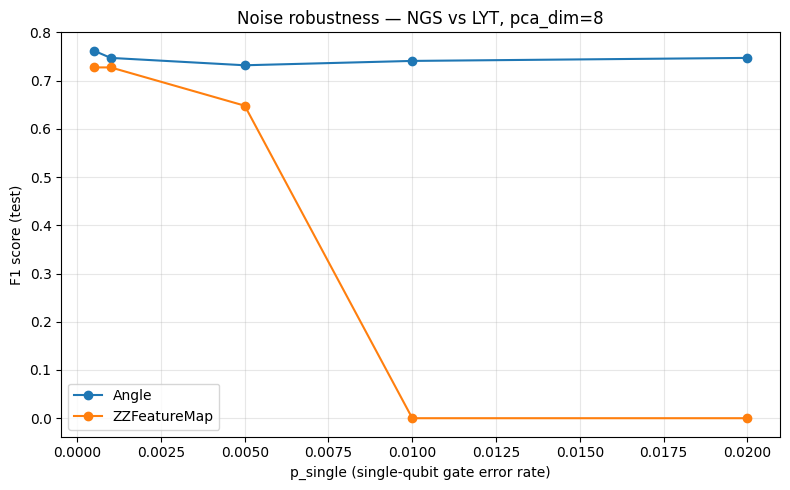

In [21]:
# ============================================================
# Noise robustness: F1 vs p_single
# ============================================================

noise_levels = [0.0005, 0.001, 0.005, 0.01, 0.02]
noise_results = []

for p in noise_levels:
    sim_p = AerSimulator(
        method="density_matrix",
        noise_model=build_noise_model(p_single=p, p_two=10 * p)
    )
    row = {"p_single": p}

    # FIX: use default argument `s=sim_p` to capture the current value
    # (avoids late-binding closure bug)
    noise_kernel_fns = [
        ("Angle",        lambda Xa, Xb, s=sim_p: compute_dm_kernel(angle_encoding, Xa, Xb, sim=s)),
        ("ZZFeatureMap", lambda Xa, Xb, s=sim_p: compute_dm_kernel(zz_circuit,     Xa, Xb, sim=s)),
    ]

    for enc_name, cfn in noise_kernel_fns:
        K_tr = cfn(X_train_q, X_train_q)
        K_te = cfn(X_test_q,  X_train_q)
        gs_n = GridSearchCV(SVC(kernel="precomputed"), param_grid_qsvm,
                            scoring="f1", cv=cv_qsvm, refit=True)
        gs_n.fit(K_tr, y_train_bin)
        y_pred = gs_n.best_estimator_.predict(K_te)
        row[enc_name] = f1_score(y_test_bin, y_pred, pos_label=1)
        print(f"  p={p:.4f}  {enc_name}: F1={row[enc_name]:.4f}")
    noise_results.append(row)

df_noise = pd.DataFrame(noise_results)
print("\nF1 vs p_single:")
print(df_noise.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
for col in ["Angle", "ZZFeatureMap"]:
    ax.plot(df_noise["p_single"], df_noise[col], marker="o", label=col)
ax.set_xlabel("p_single (single-qubit gate error rate)")
ax.set_ylabel("F1 score (test)")
ax.set_title(f"Noise robustness — {class_pos} vs {class_neg}, pca_dim={pca_dim}")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Final comparison: SVM vs QSVM (ideal) vs QSVM (noisy)

Delta F1 is always computed against the **best classical SVM baseline** (PCA + RBF).


In [22]:
# ============================================================
# Final comparison: SVM vs QSVM (ideal) vs QSVM (noisy)
# ============================================================

cols_metrics = ["Accuracy_test", "F1_test", "BalancedAcc_test"]

# --- Build comparison DataFrame ---
df_svm_cmp = df_svm[["Encoding"] + cols_metrics].copy()
df_svm_cmp.columns = ["Encoding", "Acc (SVM)", "F1 (SVM)", "BAcc (SVM)"]

qsvm_to_encoding = {
    "QSVM Angle":              "Angle",
    "QSVM Amplitude":          "Amplitude",
    "QSVM Basis":              "Basis",
    "QSVM ZZFeatureMap":       "ZZFeatureMap",
    "QSVM Angle (noisy)":      "Angle",
    "QSVM ZZFeatureMap (noisy)": "ZZFeatureMap",
}

def prep_qsvm_cmp(df_q, suffix):
    df = df_q[["Encoding"] + cols_metrics].copy()
    df["Encoding"] = df["Encoding"].map(qsvm_to_encoding)
    df.columns = ["Encoding", f"Acc ({suffix})", f"F1 ({suffix})", f"BAcc ({suffix})"]
    return df

df_ideal_cmp = prep_qsvm_cmp(df_qsvm,       "QSVM")
df_noisy_cmp = prep_qsvm_cmp(df_qsvm_noisy, "QSVM noisy")

df_compare = pd.merge(df_svm_cmp,  df_ideal_cmp, on="Encoding", how="outer")
df_compare = pd.merge(df_compare,  df_noisy_cmp, on="Encoding", how="outer")

# Delta F1 against the BEST classical baseline (PCA sweep)
df_compare["ΔF1 vs best classical"] = (
    df_compare["F1 (QSVM)"] - best_classical_f1
).apply(lambda d: f"{d:+.4f}" if pd.notna(d) else "—")

df_compare["ΔF1 noisy vs best classical"] = (
    df_compare["F1 (QSVM noisy)"] - best_classical_f1
).apply(lambda d: f"{d:+.4f}" if pd.notna(d) else "—")

df_compare = df_compare.sort_values("F1 (QSVM)", ascending=False, na_position="last")

display_cols = [
    "Encoding", "F1 (SVM)", "F1 (QSVM)", "ΔF1 vs best classical",
    "F1 (QSVM noisy)", "ΔF1 noisy vs best classical",
]
print(f"SVM vs QSVM — {class_pos} vs {class_neg}, pca_dim={pca_dim}")
print(f"Best classical baseline: F1={best_classical_f1:.4f} (PCA dim={best_classical_dim})")
print()
print(df_compare[display_cols].round(4).to_string(index=False))


SVM vs QSVM — NGS vs LYT, pca_dim=8
Best classical baseline: F1=0.8764 (PCA dim=16)

       Encoding  F1 (SVM)  F1 (QSVM) ΔF1 vs best classical  F1 (QSVM noisy) ΔF1 noisy vs best classical
          Angle    0.6747     0.7619               -0.1145           0.7470                     -0.1294
   ZZFeatureMap       NaN     0.7273               -0.1491           0.7273                     -0.1491
      Amplitude    0.7250     0.6364               -0.2400              NaN                           —
          Basis    0.6353     0.4789               -0.3975              NaN                           —
Classical (PCA)    0.7711        NaN                     —              NaN                           —


## Diagnostic plots: confusion matrices & classification reports


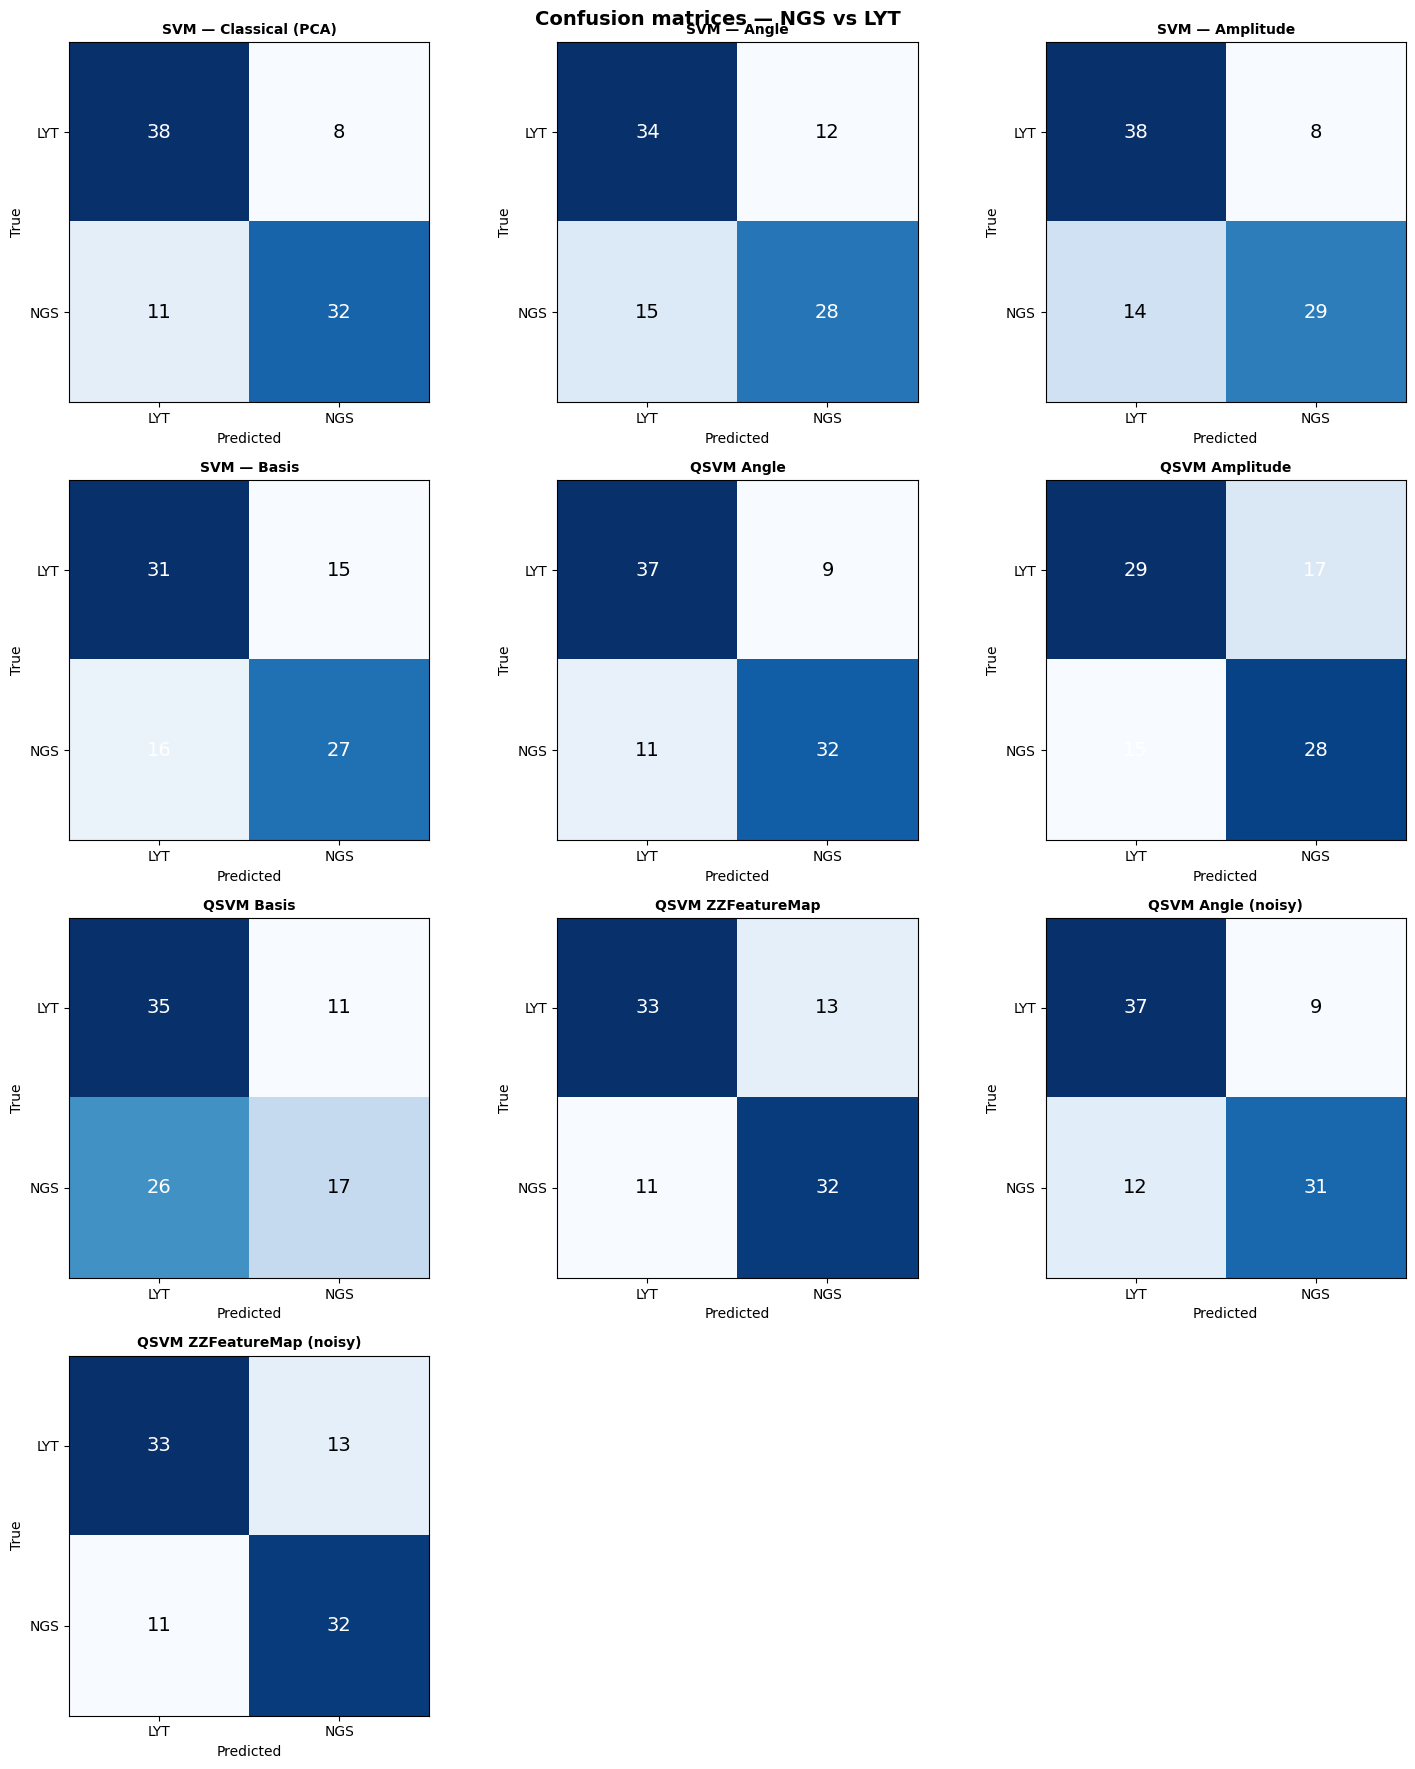


Classification Report: SVM — Classical (PCA)
              precision    recall  f1-score   support

         LYT       0.78      0.83      0.80        46
         NGS       0.80      0.74      0.77        43

    accuracy                           0.79        89
   macro avg       0.79      0.79      0.79        89
weighted avg       0.79      0.79      0.79        89


Classification Report: QSVM Angle
              precision    recall  f1-score   support

         LYT       0.77      0.80      0.79        46
         NGS       0.78      0.74      0.76        43

    accuracy                           0.78        89
   macro avg       0.78      0.77      0.77        89
weighted avg       0.78      0.78      0.77        89


Classification Report: QSVM Angle (noisy)
              precision    recall  f1-score   support

         LYT       0.76      0.80      0.78        46
         NGS       0.78      0.72      0.75        43

    accuracy                           0.76        89
   m

In [23]:
# ============================================================
# Confusion matrices for all models
# ============================================================

# Collect all predictions
all_preds = {}
for name, y_pred in svm_predictions.items():
    all_preds[f"SVM — {name}"] = y_pred
for name, y_pred in qsvm_preds.items():
    all_preds[name] = y_pred
for name, y_pred in qsvm_noisy_preds.items():
    all_preds[name] = y_pred

n_models = len(all_preds)
ncols = 3
nrows = (n_models + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes_flat = np.array(axes).flatten()

target_names = [class_neg, class_pos]  # -1, +1

for idx, (name, y_pred) in enumerate(all_preds.items()):
    ax = axes_flat[idx]
    cm = confusion_matrix(y_test_bin, y_pred, labels=[-1, 1])
    im = ax.imshow(cm, cmap="Blues", interpolation="nearest")
    ax.set_title(name, fontsize=10, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(target_names)
    ax.set_yticks([0, 1]); ax.set_yticklabels(target_names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    # Annotate cells
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")

for idx in range(n_models, len(axes_flat)):
    axes_flat[idx].set_visible(False)

plt.suptitle(f"Confusion matrices — {class_pos} vs {class_neg}", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# --- Classification reports for key models ---
key_models = {}
# Best SVM
best_svm_name = df_svm.iloc[0]["Encoding"]
if best_svm_name in svm_predictions:
    key_models[f"SVM — {best_svm_name}"] = svm_predictions[best_svm_name]
# Best QSVM ideal
if not df_qsvm.empty:
    best_qsvm_name = df_qsvm.iloc[0]["Encoding"]
    if best_qsvm_name in qsvm_preds:
        key_models[best_qsvm_name] = qsvm_preds[best_qsvm_name]
# Best QSVM noisy
if not df_qsvm_noisy.empty:
    best_qsvm_noisy_name = df_qsvm_noisy.iloc[0]["Encoding"]
    if best_qsvm_noisy_name in qsvm_noisy_preds:
        key_models[best_qsvm_noisy_name] = qsvm_noisy_preds[best_qsvm_noisy_name]

for name, y_pred in key_models.items():
    print(f"\n{'='*50}")
    print(f"Classification Report: {name}")
    print(f"{'='*50}")
    print(classification_report(y_test_bin, y_pred, target_names=target_names))
